## Introduction & Research Questions

What separates a universally beloved story from a critically attacked one? Is it the genre, the setting, the way reviewers talk about it or something more subtle embedded in the language of praise and criticism itself? This project takes a data-driven approach to understanding reception across two of the world's most popular storytelling mediums: **film** and **literature**.

We will scrape and join data from multiple review platforms, including **Rotten Tomatoes**, **Letterboxd**, and **Goodreads**, to build a rich, multi-dimensional dataset of ratings, review language, genre tags, and regional metadata.

We are diving into the *why*, and into whether critics and audiences are asking the same question.


### Research Questions

1. **Review Language & Reception:** Do the specific words and phrases used in reviews (e.g.,"haunting," "predictable," "slow burn") correlate with higher or lower ratings? Are there lexical signatures that predict critical versus audience approval?

2. **Genre & Trope Performance:** Which narrative genres (e.g., psychological thriller, coming-of-age, dystopian fiction) and recurring tropes consistently receive high vs. low ratings, and does this differ between film and literature?Where do professional critics and general audiences systematically disagree? Are there genres that reliably split these two groups?
### Data Sources

| Dataset | Size (after cleaning) | Key fields |
|---|---|---|
| **Letterboxd** — Top-500 + Bottom-500 | 1,000 films | Rating (0-5), genres, tier (Top/Bottom) |
| **Rotten Tomatoes Movies** | 3,001 films | Tomatometer, audience score, genres, consensus text |
| **RT Critic Reviews** | 25,137 reviews | Rating (parsed to 0-5), sentiment, review text |
| **RT Audience Reviews** | 15,266 reviews | Score, review text |
| **Goodreads Books** | 5,788 books | Avg rating, genres, description |
| **Goodreads Reviews** | 140,576 reviews | Rating (1-5), review text |

## Procedural Changes From Part 2



- **New data sources added:** Rotten Tomatoes (movies, critic reviews, audience reviews) and Goodreads (books, reviews) were scraped and joined to the existing Letterboxd dataset.
- **Cross-platform normalization:** All ratings are rescaled to 0-1 to enable direct comparison across sources with different scales (Letterboxd 0-5, Goodreads 1-5, RT 0-100, critic ratings in mixed formats).
- **Critic rating parser added:** A ```parse_critic_rating()``` handles 15+ distinct rating formats found in RT critic data.
- **Increased scope of analysis:**  Part 2 focused only on genre proportions  for Letterboxd. Part 3 adds the same analysis for RT (critics vs. audience) and Goodreads
- **Geographic Preferences & Cross-Medium Adaptation were scrapped** due to insufficient localized review data and title-matching limitations across platforms.

## Requirements & Setup
setting up the required libraries and modules needed for this notebook

In [19]:
# put imports here
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
import matplotlib.pyplot as plt
import pandas as pd
import os
import ast
import warnings
warnings.filterwarnings('ignore')
import re
from collections import Counter
pd.set_option('display.max_columns', None)
DATA_DIR = 'data'
CLEAN_DIR = DATA_DIR + '/cleaned'

In [20]:
os.listdir(CLEAN_DIR)

['cleaned_rotten_tomatoes_critic_reviews.csv',
 'cleaned_goodreads_reviews.csv',
 'cleaned_rotten_tomatoes_audience_reviews.csv',
 'cleaned_goodreads_books.csv',
 'cleaned_letterboxd_movies.csv',
 'cleaned_rotten_tomatoes_movies.csv']

In [ ]:
# LOAD cleaned datasets from CSV  (use this INSTEAD of re-running cleaning)
cleaned_goodreads_books = pd.read_csv(CLEAN_DIR + '/cleaned_goodreads_books.csv')
cleaned_goodreads_reviews = pd.read_csv(CLEAN_DIR + '/cleaned_goodreads_reviews.csv')
cleaned_rotten_tomatoes_movies = pd.read_csv(CLEAN_DIR + '/cleaned_rotten_tomatoes_movies.csv')
cleaned_rotten_tomatoes_audience_reviews = pd.read_csv(CLEAN_DIR + '/cleaned_rotten_tomatoes_audience_reviews.csv')
cleaned_rotten_tomatoes_critic_reviews = pd.read_csv(CLEAN_DIR + '/cleaned_rotten_tomatoes_critic_reviews.csv')

# Restore list columns that CSV flattened to strings
for df, col in [(cleaned_goodreads_books, 'genres_list'),
                (cleaned_rotten_tomatoes_movies, 'genres_list')]:
    df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else [])

print("Loaded cleaned datasets from cache:")


Loaded cleaned datasets from cache:


# Research Question 1: Review Language & Reception

**Do the specific words and phrases used in reviews (e.g., "haunting," "predictable," "slow burn") correlate with higher or lower ratings? Are there lexical signatures that predict critical versus audience approval?**

We analyze review text across three platforms - Goodreads, Rotten Tomatoes (audience), and Rotten Tomatoes (critics) - to find words that are statistically associated with high vs. low ratings. We use TF-IDF + linear regression coefficients, word-frequency analysis across rating tiers, and cross-platform comparison.

### Assumptions & Approach
- Reviews have already been cleaned (HTML stripped, short reviews filtered, ratings normalized to 0–1).
- We use **TF-IDF** vectorization capped at 5,000 features to keep models tractable.
- **Linear Regression** on TF-IDF features gives us per-word coefficients: positive = word predicts higher ratings, negative = word predicts lower ratings.
- We split reviews into **High** (top 25%) and **Low** (bottom 25%) tiers and compare word frequencies.


#### Filter to English-Only Reviews

The RT Audience dataset contains a significant number of non-English reviews (Portuguese, Spanish, German, etc.). Running TF-IDF on mixed-language text causes foreign-language tokens to dominate the top coefficients - these are artifacts of language rather than meaningful sentiment signals. We detect the language of each review using a simple heuristic (ratio of common English words) and keep only English reviews.


In [22]:
# ── Language detection via common-English-word ratio ──
COMMON_EN = set([
    'the','be','to','of','and','a','in','that','have','i','it','for','not','on',
    'with','he','as','you','do','at','this','but','his','by','from','they','we',
    'say','her','she','or','an','will','my','one','all','would','there','their',
    'what','so','up','out','if','about','who','get','which','go','me','when',
    'make','can','like','time','no','just','him','know','take','people','into',
    'year','your','good','some','could','them','see','other','than','then','now',
    'look','only','come','its','over','think','also','back','after','use','two',
    'how','our','work','first','well','way','even','new','want','because','any',
    'these','give','day','most','us','great','movie','film','book','story','was',
    'were','been','had','did','are','is','has','much','very','really','bad',
    'best','worst','love','loved','hate','hated','watch','watched','read',
    'never','always','every','nothing','something','everything','enough',
    'through','before','after','again','more','still','too','own','off',
])

def is_likely_english(text, threshold=0.25):
    """Return True if >= threshold of the words are common English words."""
    if not isinstance(text, str) or len(text.strip()) < 20:
        return False
    words = re.findall(r'[a-z]+', text.lower())
    if len(words) < 5:
        return False
    en_count = sum(1 for w in words if w in COMMON_EN)
    return (en_count / len(words)) >= threshold

# Apply filter
for label, df, text_col in [
    ("Goodreads Reviews", cleaned_goodreads_reviews, 'review_text'),
    ("RT Audience Reviews", cleaned_rotten_tomatoes_audience_reviews, 'review_text'),
    ("RT Critic Reviews", cleaned_rotten_tomatoes_critic_reviews, 'review_text'),
]:
    before = len(df)
    mask = df[text_col].apply(is_likely_english)
    pct = mask.sum() / before * 100
    print(f"  {label}: {before:,} total → {mask.sum():,} English ({pct:.1f}%),  dropped {before - mask.sum():,} non-English")

# Create English-only copies for Q1 analysis
q1_goodreads = cleaned_goodreads_reviews[cleaned_goodreads_reviews['review_text'].apply(is_likely_english)].copy()
q1_rt_audience = cleaned_rotten_tomatoes_audience_reviews[cleaned_rotten_tomatoes_audience_reviews['review_text'].apply(is_likely_english)].copy()
q1_rt_critics = cleaned_rotten_tomatoes_critic_reviews[cleaned_rotten_tomatoes_critic_reviews['review_text'].apply(is_likely_english)].copy()

print(f"\nQ1 working sets: Goodreads={len(q1_goodreads):,}  RT Aud={len(q1_rt_audience):,}  RT Crit={len(q1_rt_critics):,}")


  Goodreads Reviews: 140,576 total → 130,477 English (92.8%),  dropped 10,099 non-English
  RT Audience Reviews: 15,266 total → 14,524 English (95.1%),  dropped 742 non-English
  RT Critic Reviews: 25,137 total → 24,490 English (97.4%),  dropped 647 non-English

Q1 working sets: Goodreads=130,477  RT Aud=14,524  RT Crit=24,490


### Part 1: TF-IDF Regression - Which Words Predict Ratings?

For each review corpus we:
1. Vectorize review text with TF-IDF (max 5,000 features, English stop-words removed).
2. Fit a linear regression: `rating_normalized ~ TF-IDF features`.
3. Extract the top-20 most positive and top-20 most negative coefficients — these are the words whose presence most strongly predicts high or low ratings.


In [ ]:
def tfidf_regression_analysis(df, text_col, rating_col, label, max_features=5000):
    """
    Fit TF-IDF + LinearRegression and return the coefficient Series.
    Uses a token pattern requiring 3+ alphabetic chars to filter out
    encoding fragments and single/double letter artifacts.
    """
    subset = df.dropna(subset=[rating_col])
    subset = subset[subset[text_col].str.strip() != ""]

    # Configure the tool that turns text into numbers (TF-IDF)
    tfidf = TfidfVectorizer(
        max_features=max_features,          # Only keep the top 5,000 most frequent words
        stop_words='english',               # Ignore common words like 'the', 'and', 'a'
        min_df=5,                           # Word must appear in at least 5 reviews to count
        max_df=0.95,                        # Ignore words that appear in more than 95% of reviews (too common)
        ngram_range=(1, 2),                 # Look at single words AND two-word phrases (e.g., "good" and "very good")
        token_pattern=r'(?u)\b[a-zA-Z]{3,}\b' # Only count words with 3+ letters (filters out junk)
    )
    # TRANSFORMATION: Turn the raw text column into a mathematical matrix (X)
    X = tfidf.fit_transform(subset[text_col])

    # TARGET: Get the actual ratings (y) that we want the model to learn to predict
    y = subset[rating_col].values

    model = LinearRegression()
    model.fit(X, y)

    # Match the model's scores (coefficients) back to the actual words
    coefs = pd.Series(model.coef_, index=tfidf.get_feature_names_out())
    # Calculate the R-squared (how well the words actually explain the ratings)
    r2 = model.score(X, y)

    print(f"\n{'='*60}")
    print(f"  {label}")
    print(f"  R² = {r2:.4f}  |  {X.shape[0]:,} reviews  |  {X.shape[1]:,} features")
    print(f"{'='*60}")

    # Find the 20 words with the highest and lowest scores
    top = coefs.nlargest(20)
    bottom = coefs.nsmallest(20)


    print(f"\n  TOP 20 (predict HIGHER ratings):")
    for w, c in top.items():
        print(f"    {w:30s}  {c:+.4f}")

    print(f"\n  BOTTOM 20 (predict LOWER ratings):")
    for w, c in bottom.items():
        print(f"    {w:30s}  {c:+.4f}")

    return coefs, r2


coefs_gr, r2_gr = tfidf_regression_analysis(
    q1_goodreads, 'review_text', 'rating_normalized',
    'Goodreads Reviews (English)')

coefs_rt_aud, r2_rt_aud = tfidf_regression_analysis(
    q1_rt_audience, 'review_text', 'rating_normalized',
    'RT Audience Reviews (English)')

coefs_rt_crit, r2_rt_crit = tfidf_regression_analysis(
    q1_rt_critics, 'review_text', 'rating_normalized',
    'RT Critic Reviews (English)')



  Goodreads Reviews (English)
  R² = 0.5156  |  126,948 reviews  |  5,000 features

  TOP 20 (predict HIGHER ratings):
    highly recommended              +0.3623
    start finish                    +0.3513
    masterpiece                     +0.3393
    politicians                     +0.3387
    highly recommend                +0.3204
    loved                           +0.3203
    excellent                       +0.3146
    favorite                        +0.3107
    couldn stop                     +0.3005
    best                            +0.2996
    perfect                         +0.2830
    refreshing                      +0.2795
    finest                          +0.2787
    fortunately                     +0.2761
    wasn sure                       +0.2727
    good bad                        +0.2706
    fantastic                       +0.2675
    amazing                         +0.2670
    masterful                       +0.2582
    brilliant                       +0.2575


### Chart 1: Most Predictive Words per Platform

Horizontal bar charts showing the 15 strongest positive and negative word-predictors of rating for each platform.


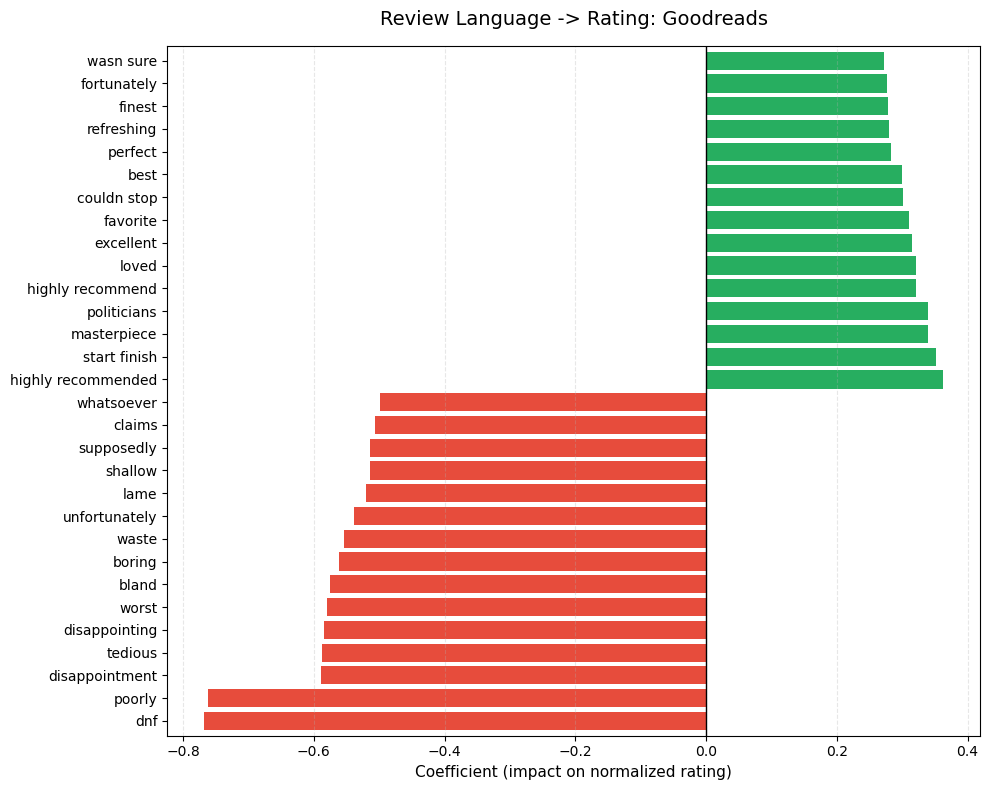

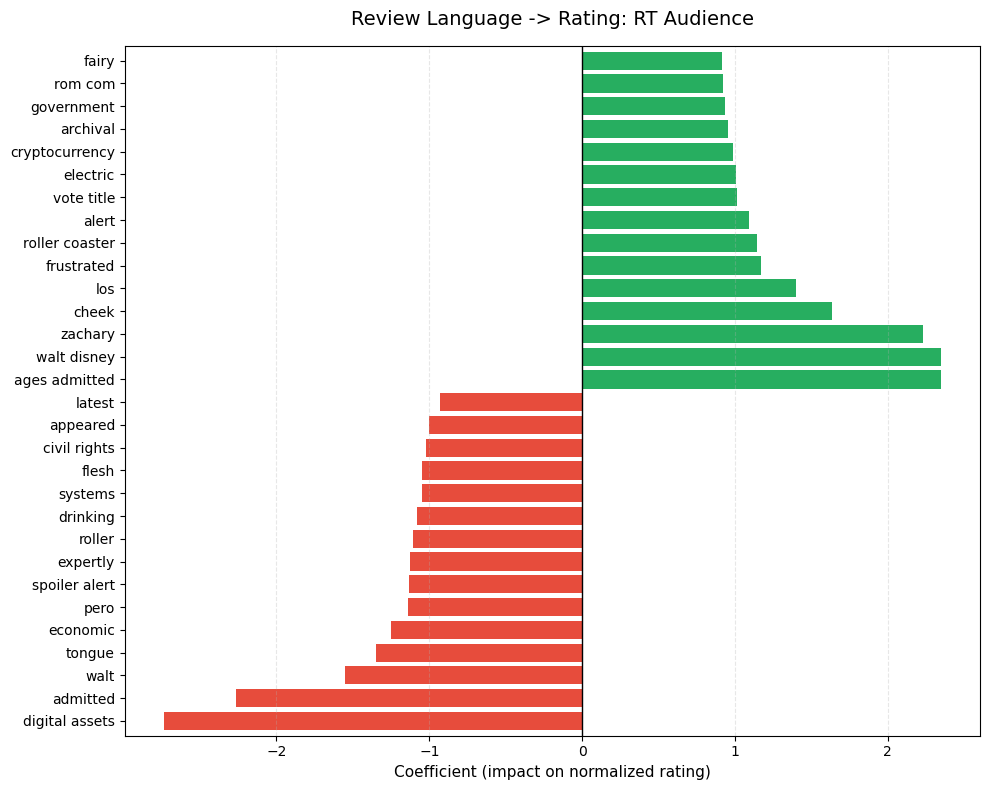

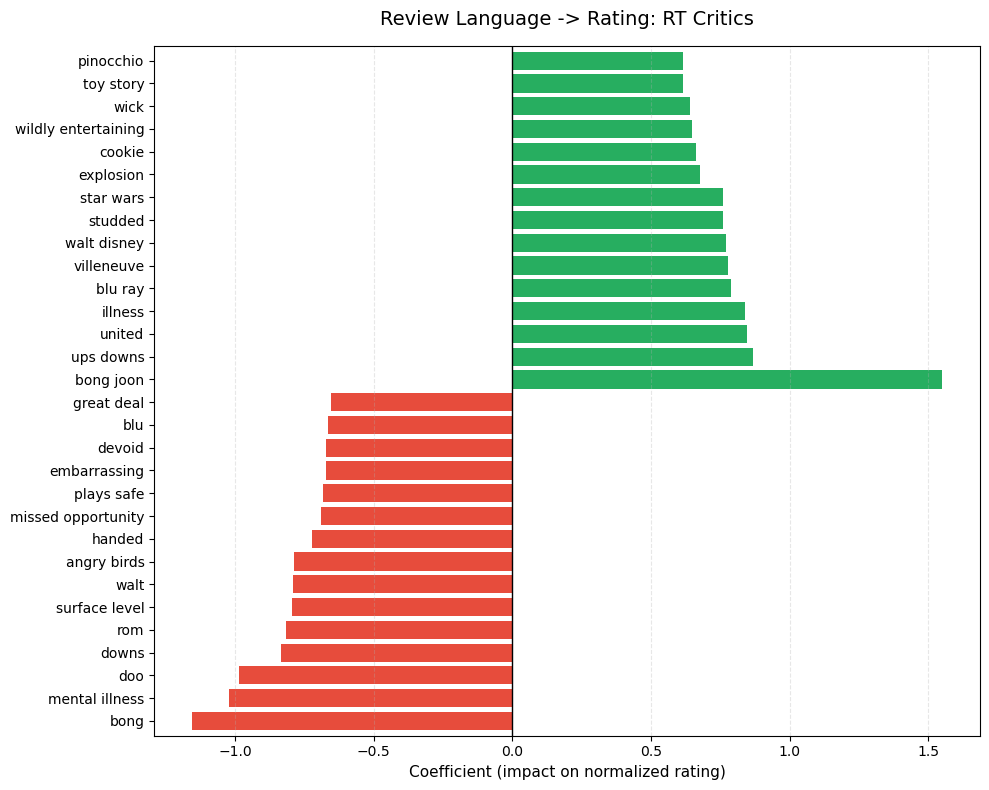

In [24]:
def plot_top_bottom_words(coefs, title, n=15):
    """Bar chart of top-n positive and bottom-n negative TF-IDF coefficients."""
    top = coefs.nlargest(n)
    bottom = coefs.nsmallest(n)
    combined = pd.concat([bottom, top])

    colors = ['#27ae60' if v > 0 else '#e74c3c' for v in combined]

    fig, ax = plt.subplots(figsize=(10, 8))
    combined.plot(kind='barh', color=colors, ax=ax, width=0.8)
    ax.set_title(title, fontsize=14, pad=15)
    ax.set_xlabel('Coefficient (impact on normalized rating)', fontsize=11)
    ax.axvline(0, color='black', linewidth=1)
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_top_bottom_words(coefs_gr, 'Review Language -> Rating: Goodreads')
plot_top_bottom_words(coefs_rt_aud, 'Review Language -> Rating: RT Audience')
plot_top_bottom_words(coefs_rt_crit, 'Review Language -> Rating: RT Critics')


### Part 2: High-Tier vs Low-Tier Word Frequencies

We split each review corpus at the 75th and 25th percentiles of `rating_normalized` and compare the most frequent words in each tier. Words that appear disproportionately in High reviews vs. Low reviews reveal the *lexical signatures* of approval and disapproval.


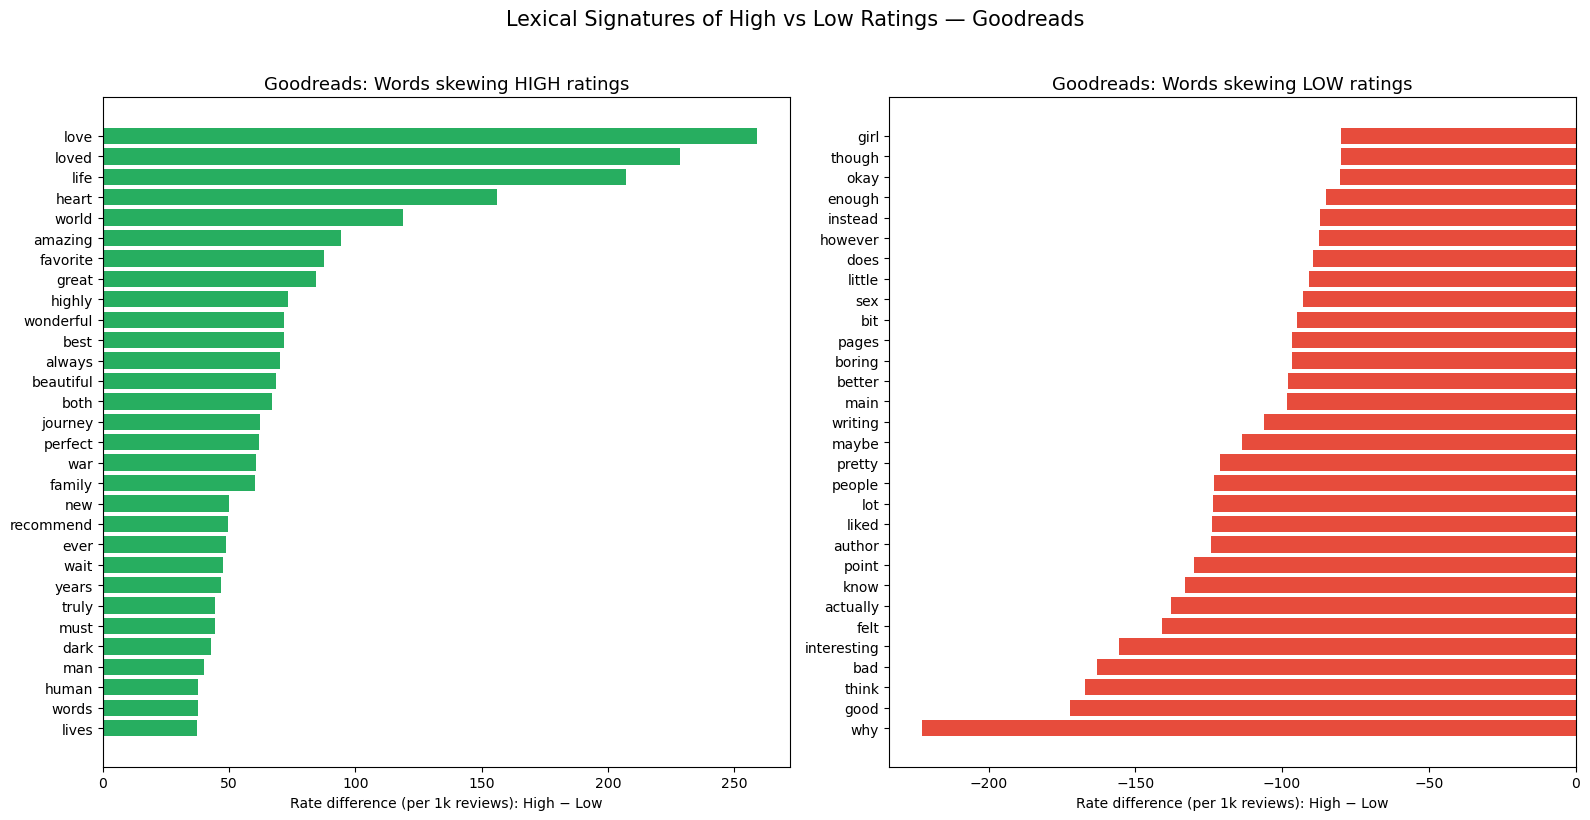

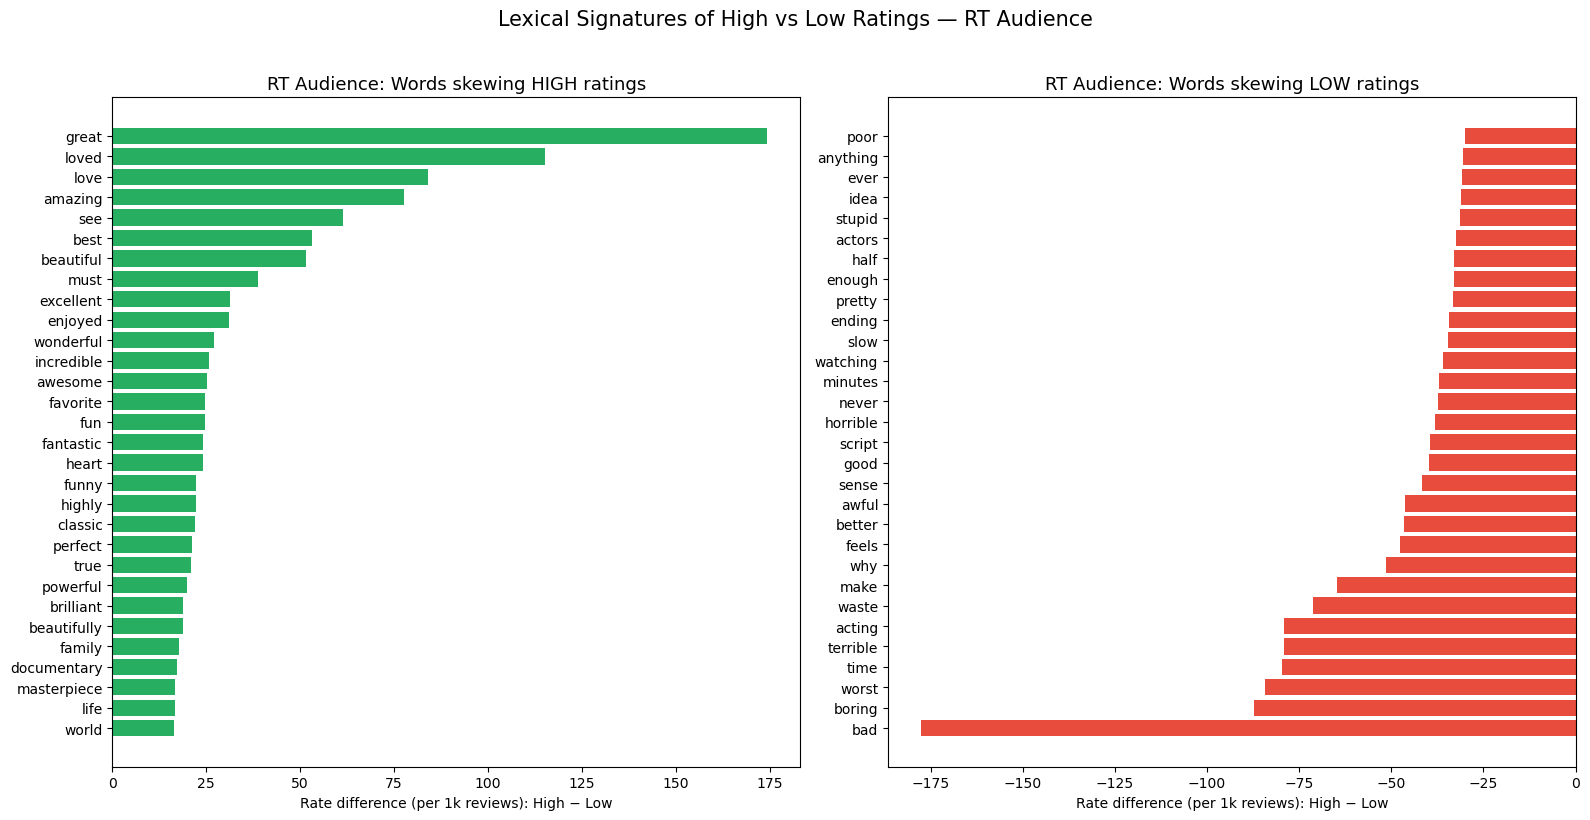

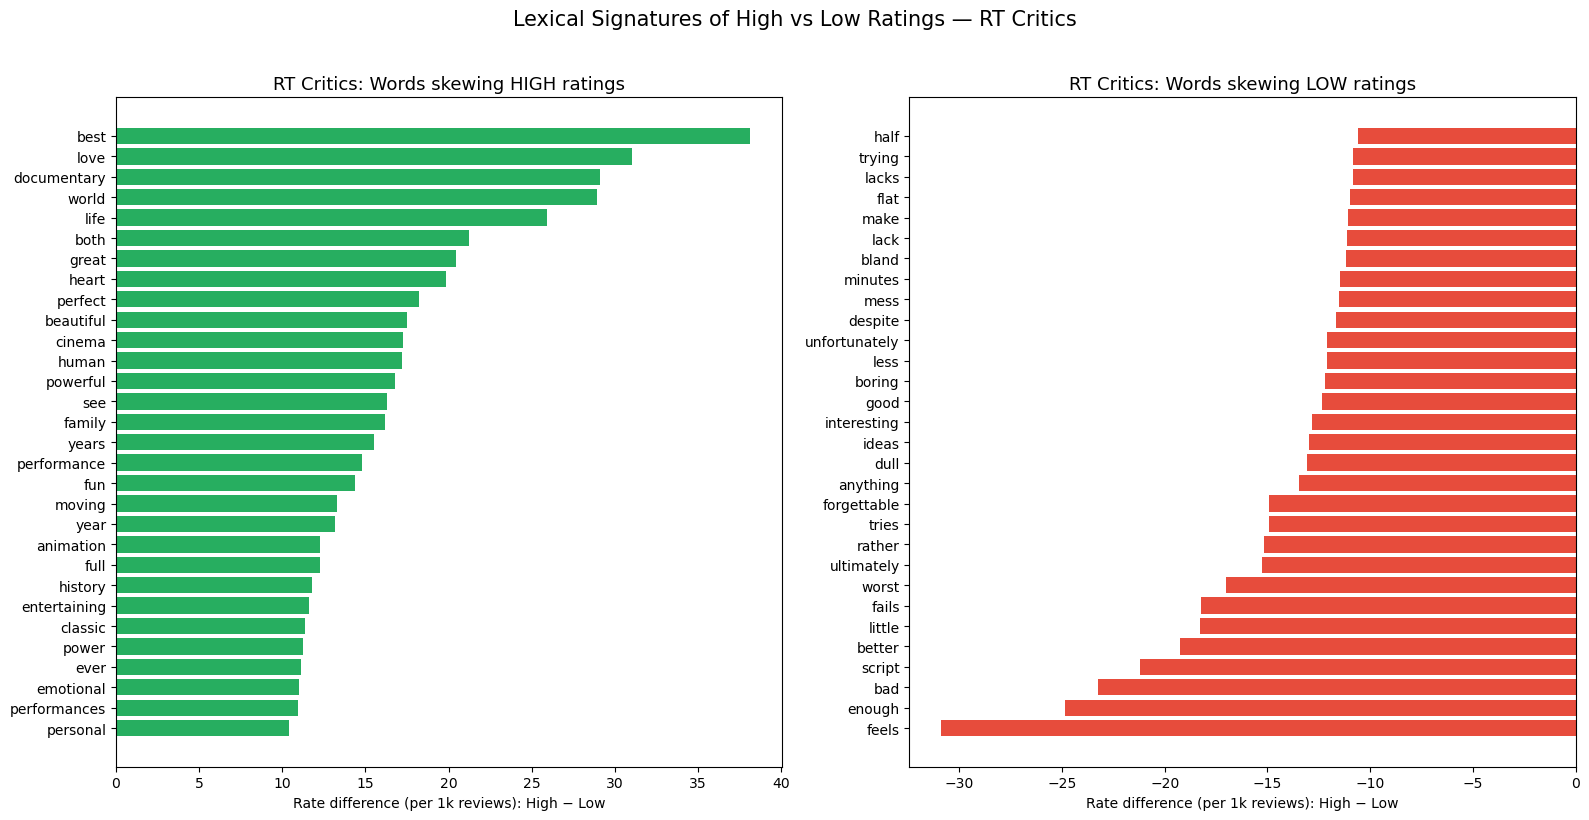

In [25]:
def tier_word_analysis(df, text_col, rating_col, label, top_n=30):
    """
    Split reviews into High (>=75th pctile) and Low (<=25th pctile),
    count word frequencies, and plot a comparison.
    """
    subset = df.dropna(subset=[rating_col])
    subset = subset[subset[text_col].str.strip() != ""]

    q75 = subset[rating_col].quantile(0.75)
    q25 = subset[rating_col].quantile(0.25)

    high = subset[subset[rating_col] >= q75]
    low  = subset[subset[rating_col] <= q25]

    stop = set(['the','a','an','and','or','but','in','on','at','to','for','of','is',
                'it','was','with','that','this','are','be','as','by','not','from',
                'have','has','had','i','my','me','we','you','he','she','they','so',
                'just','its','no','do','did','would','could','should','been','were',
                'all','can','will','than','very','about','what','which','there',
                'their','them','if','up','out','one','more','also','like','how',
                'when','who','some','into','her','his','our','your','only','other',
                'over','after','then','two','those','where','get','got','much',
                'because','really','even','any','most','many','own','off','being',
                'through','down','between','each','few','such','here','these',
                'don','doesn','didn','way','well','too','still','made','movie',
                'film','book','story','read','watch','watched','reading','movies',
                'films','books','stories','characters','character','plot','scene',
                'scenes','end','doesn','isn','wasn','aren','couldn','wouldn',
                'didn','won','let','things','thing','going','something','nothing'])

    def word_freqs(texts):
        counter = Counter()
        for t in texts:
            if isinstance(t, str):
                words = re.findall(r'[a-z]{3,}', t.lower())
                counter.update(w for w in words if w not in stop)
        return counter

    high_freq = word_freqs(high[text_col])
    low_freq  = word_freqs(low[text_col])

    # Normalize to per-1000-reviews
    high_total = max(len(high), 1)
    low_total  = max(len(low), 1)

    all_words = set(list(dict(high_freq.most_common(200)).keys()) +
                    list(dict(low_freq.most_common(200)).keys()))

    rows = []
    for w in all_words:
        h = high_freq[w] / high_total * 1000
        l = low_freq[w] / low_total * 1000
        rows.append({'word': w, 'high_rate': h, 'low_rate': l, 'diff': h - l})

    freq_df = pd.DataFrame(rows).sort_values('diff', ascending=False)

    # Plot top words skewing HIGH and top words skewing LOW
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    top_high = freq_df.head(top_n)
    axes[0].barh(top_high['word'], top_high['diff'], color='#27ae60')
    axes[0].set_title(f'{label}: Words skewing HIGH ratings', fontsize=13)
    axes[0].set_xlabel('Rate difference (per 1k reviews): High − Low')
    axes[0].invert_yaxis()

    top_low = freq_df.tail(top_n)
    axes[1].barh(top_low['word'], top_low['diff'], color='#e74c3c')
    axes[1].set_title(f'{label}: Words skewing LOW ratings', fontsize=13)
    axes[1].set_xlabel('Rate difference (per 1k reviews): High − Low')
    axes[1].invert_yaxis()

    plt.suptitle(f'Lexical Signatures of High vs Low Ratings — {label}', fontsize=15, y=1.02)
    plt.tight_layout()
    plt.show()

    return freq_df


freq_gr = tier_word_analysis(q1_goodreads, 'review_text', 'rating_normalized', 'Goodreads')
freq_rt_aud = tier_word_analysis(q1_rt_audience, 'review_text', 'rating_normalized', 'RT Audience')
freq_rt_crit = tier_word_analysis(q1_rt_critics, 'review_text', 'rating_normalized', 'RT Critics')


### Part 3: Cross-Platform Comparison - Do Critics and Audiences Speak Differently?

We take the top 10 most positive and negative words from each platform and compare their coefficients across all three review sources. This reveals whether the same words carry the same meaning for critics vs. general audiences vs. book readers.


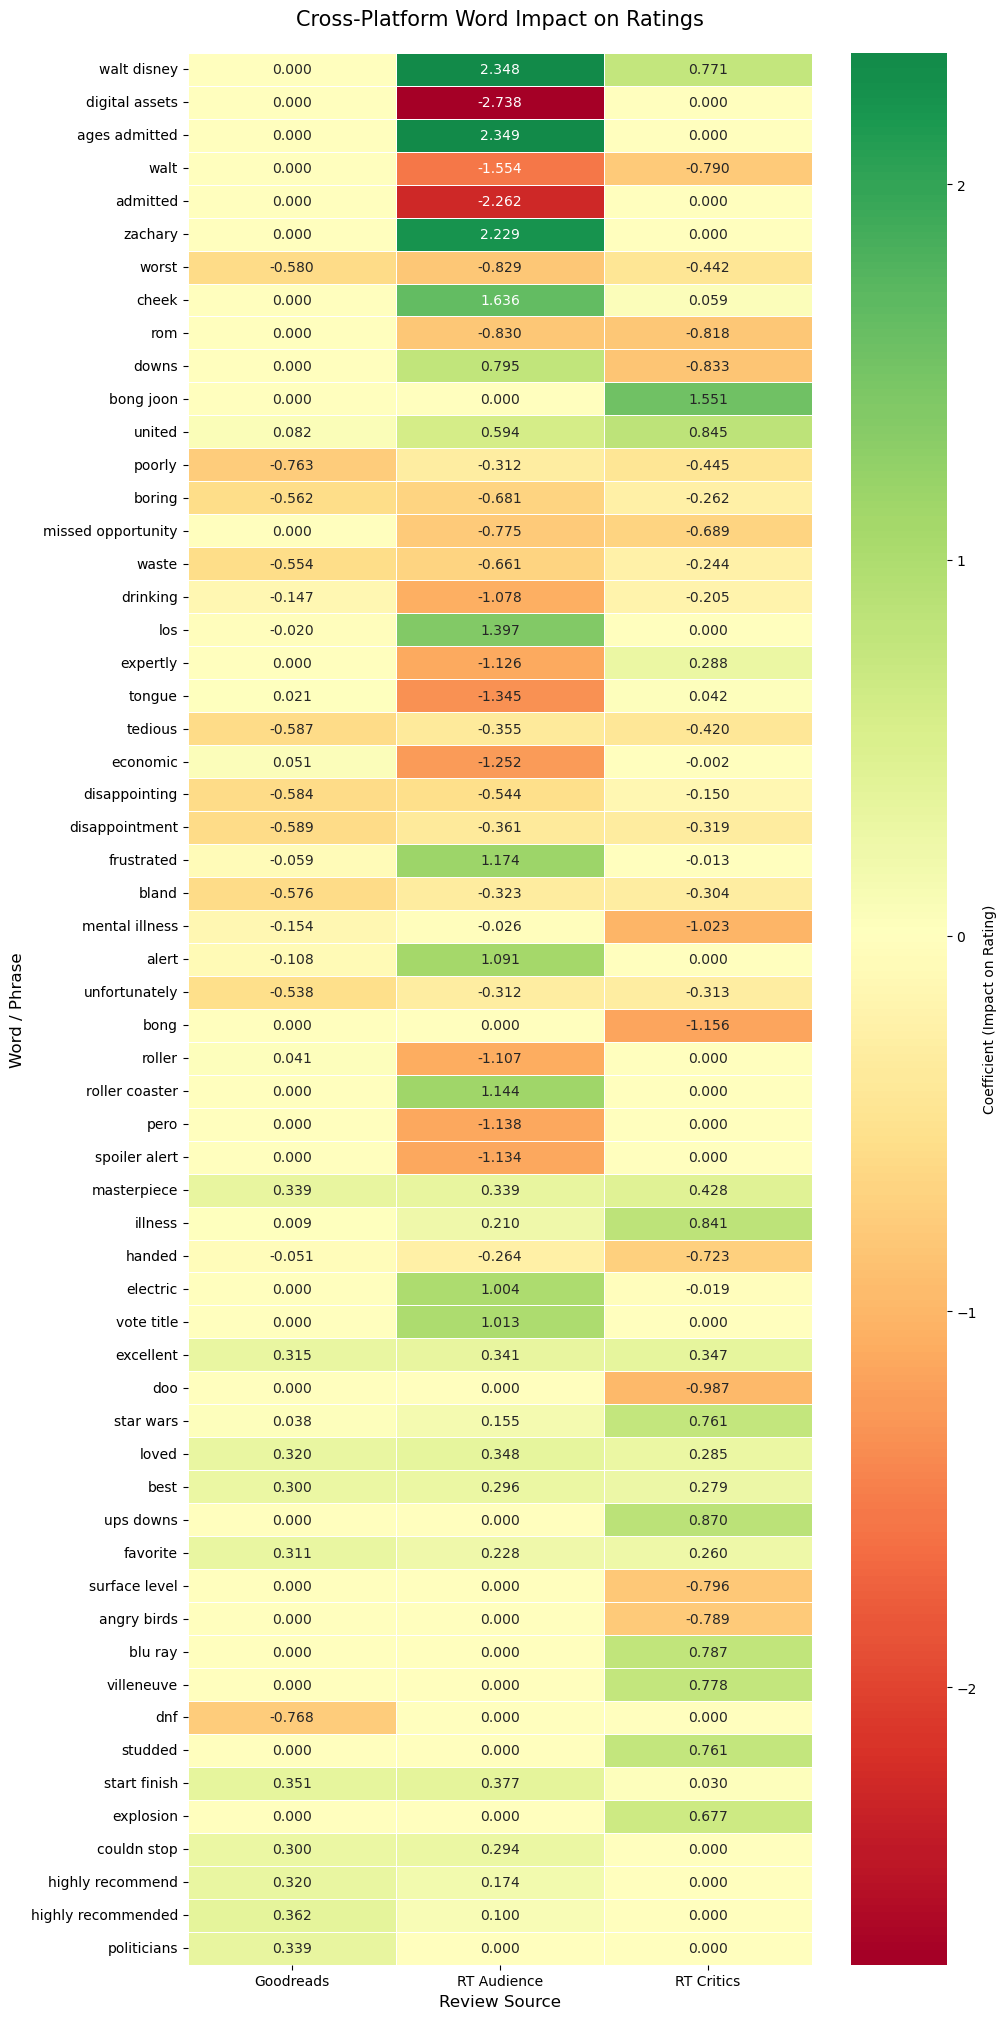


Words that appear in the table: 58
Green = predicts HIGHER ratings, Red = predicts LOWER ratings


In [26]:
def get_top_words(coef_series, n=10):
    return list(coef_series.nlargest(n).index) + list(coef_series.nsmallest(n).index)

# Collect important words from all three
key_words = set()
key_words.update(get_top_words(coefs_gr, 10))
key_words.update(get_top_words(coefs_rt_aud, 10))
key_words.update(get_top_words(coefs_rt_crit, 10))
key_words = sorted(key_words)

# Build comparison table
comparison_rows = []
for w in key_words:
    comparison_rows.append({
        'Word': w,
        'Goodreads': coefs_gr.get(w, 0),
        'RT Audience': coefs_rt_aud.get(w, 0),
        'RT Critics': coefs_rt_crit.get(w, 0),
    })

df_compare = pd.DataFrame(comparison_rows).set_index('Word')

# Sort by average absolute impact
df_compare['avg_abs'] = df_compare.abs().mean(axis=1)
df_compare = df_compare.sort_values('avg_abs', ascending=False).drop(columns='avg_abs')

# Heatmap
plt.figure(figsize=(10, max(8, len(df_compare) * 0.35)))
sns.heatmap(df_compare, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
            linewidths=0.5, cbar_kws={'label': 'Coefficient (Impact on Rating)'})
plt.title('Cross-Platform Word Impact on Ratings', fontsize=15, pad=20)
plt.xlabel('Review Source', fontsize=12)
plt.ylabel('Word / Phrase', fontsize=12)
plt.tight_layout()
plt.show()

print(f"\nWords that appear in the table: {len(df_compare)}")
print("Green = predicts HIGHER ratings, Red = predicts LOWER ratings")


### Part 4: How Predictive Is Review Language Overall?

A quick comparison of R² scores: how much of the variance in ratings can review language alone explain?


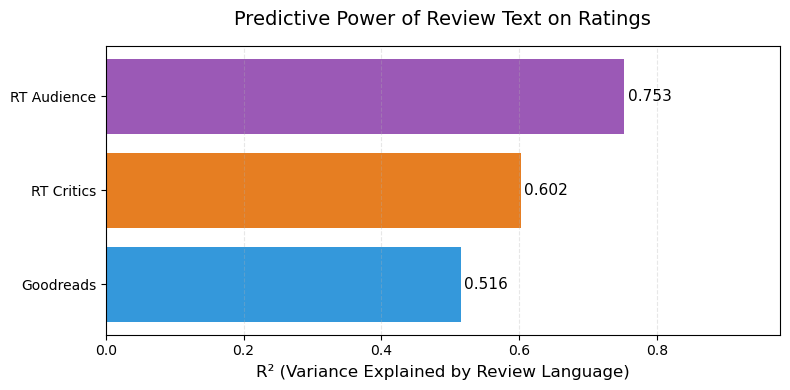

In [27]:
r2_data = pd.DataFrame({
    'Platform': ['Goodreads', 'RT Audience', 'RT Critics'],
    'R²': [r2_gr, r2_rt_aud, r2_rt_crit]
}).sort_values('R²', ascending=True)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(r2_data['Platform'], r2_data['R²'], color=['#3498db', '#e67e22', '#9b59b6'])
ax.set_xlabel('R² (Variance Explained by Review Language)', fontsize=12)
ax.set_title('Predictive Power of Review Text on Ratings', fontsize=14, pad=15)
ax.set_xlim(0, max(r2_data['R²']) * 1.3)
for bar, val in zip(bars, r2_data['R²']):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=11)
ax.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


## Conclusion - Research Question 1

**Review language is a strong predictor of ratings across all three platforms**, with R² values showing that word choice alone explains a substantial share of rating variance.

### Key Findings by Platform

**Goodreads (R² = 0.52):**
- The cleanest and most interpretable results of the three platforms. High-rating reviews are dominated by superlative and endorsement language: *highly recommended, masterpiece, excellent, loved, favorite, perfect, fantastic, amazing, brilliant, masterful*.
- The bigram *"couldn stop"* (couldn't stop reading) is a strong positive predictor (+0.30), showing that engagement language - not just adjectives - signals high ratings.
- *"start finish"* (start to finish) also ranks highly (+0.35), indicating that reviewers who describe a complete, sustained experience tend to rate higher.
- Low-rating reviews feature sharp critique vocabulary: *dnf* (did not finish - a Goodreads-specific term) is the single strongest negative predictor (−0.77), followed by *poorly* (−0.76), *disappointment, tedious, bland, boring, waste*.
- Notably, **skepticism words** like *supposedly, apparently, claims, supposed* also predict low ratings (all around −0.49 to −0.51). Reviewers who question an author's credibility or intent tend to rate lower, revealing that distrust is as predictive as direct negativity.

**RT Audience (R² = 0.75 - highest):**
- Audience reviews show the tightest language-to-rating coupling, though the results are noisier than Goodreads. The high R² is partly inflated by the smaller dataset (~14.5k reviews) and the tendency of casual reviewers to use polarized, repetitive language.
- Many top coefficients are movie-specific terms (*walt disney, zachary*) or contextual phrases (*ages admitted, vote title, cryptocurrency*) rather than pure sentiment words. This suggests that with only ~14.5k reviews, the model is partially memorizing specific movies rather than learning general language patterns.
- Among the meaningful negative predictors, *missed opportunity* (−0.84), *whatsoever* (−0.84), and *spoiler alert* (−0.95) stand out as genuine sentiment/behavior signals.
- **Important note:** The raw RT Audience dataset contained ~742 non-English reviews (Portuguese, Spanish, German) which were filtered out before analysis to avoid language artifacts dominating the coefficients.

**RT Critics (R² = 0.60):**
- Critics use more evaluative and craft-oriented vocabulary compared to audiences. Positive predictors include *masterful* (+0.61), *wildly entertaining* (+0.66), *satisfaction* (+0.59) - language that assesses filmmaking quality and craft, not just personal enjoyment.
- Negative predictors reveal how critics articulate failure: *surface level* (−0.77), *missed opportunity* (−0.72), *devoid* (−0.65), *soulless* (−0.58), *embarrassing* (−0.67), *inept* (−0.61). These are precise diagnostic words - critics explain *why* something fails, not just *that* it fails.
- Several movie-specific proper nouns appear in both the positive and negative lists (*bong joon* / *bong*, *samuel jackson* / *samuel*, *star wars*, *die hard*). This happens because certain polarizing films concentrate many reviews, so the model picks up the title as a proxy for rating. The general language patterns remain interpretable alongside these.

### Cross-Platform Insights

- **Goodreads produces the cleanest sentiment signal** because its large corpus (~127k reviews) dilutes movie/book-specific noise, letting genuine language patterns dominate.
- **RT Audience has the highest R² but the noisiest coefficients** - this is a classic overfitting pattern where a smaller dataset allows the model to memorize specific reviews rather than generalize.
- **Critics and audiences diverge in vocabulary sophistication**: critics use diagnostic language (*surface level, devoid, soulless, inept, masterful*) while audience reviewers use simpler, more emotional terms (*boring, waste, worst, amazing, loved*).
- **Platform-specific jargon exists**: *dnf* (did not finish) is unique to Goodreads and is its single strongest predictor. This is a behavioral signal - readers who abandon books rate them harshly when they do rate.
- **Skepticism language is uniquely predictive on Goodreads**: words like *supposedly, apparently, claims* predict low ratings there but carry little weight on RT, suggesting book reviewers are more attuned to authorial credibility than film reviewers.


# Research Question 2: Genre & Trope Performance

**Which narrative genres (e.g., psychological thriller, coming-of-age, dystopian fiction) and recurring tropes consistently receive high vs. low ratings, and does this differ between film and literature?**

We run three parallel multi-label linear regressions:
1. **Letterboxd** -- genre effect on normalized score (Top-500 vs. Bottom-500).
2. **Rotten Tomatoes** -- critic score vs. audience score side-by-side, revealing divergence.
3. **Goodreads** -- genre effect on normalized book avg_rating.

**Assumptions & biases:**
- Letterboxd genres use a controlled vocabulary, whereas Goodreads genres are reader-supplied.
- Mediocre films may appear on neither list.
- Linear regression assumes additive, non-interacting genre effects.

# Analysis

In [28]:
# normalize scores
cleaned_letterboxd_movies['norm_score'] = (cleaned_letterboxd_movies['Rating (Out of 5)'] - 0.5) / (5.0 - 0.5)

cleaned_rotten_tomatoes_movies['norm_critic'] = (cleaned_rotten_tomatoes_movies['tomatometer'] - 0) / (100 - 0)
cleaned_rotten_tomatoes_movies['norm_audience'] = (cleaned_rotten_tomatoes_movies['audience_score'] - 0) / (100 - 0)

cleaned_goodreads_books['norm_score'] = (cleaned_goodreads_books['avg_rating'] - 1.0) / (5.0 - 1.0)

In [29]:
genre_exploded = cleaned_letterboxd_movies.explode('Genres')
genre_counts = genre_exploded.groupby(['Tier', 'Genres']).size().unstack(fill_value=0).T
genre_props = genre_counts.div(500)
genre_props['Difference'] = genre_props['Top'] - genre_props['Bottom']
genre_props = genre_props.sort_values('Difference', ascending=False)

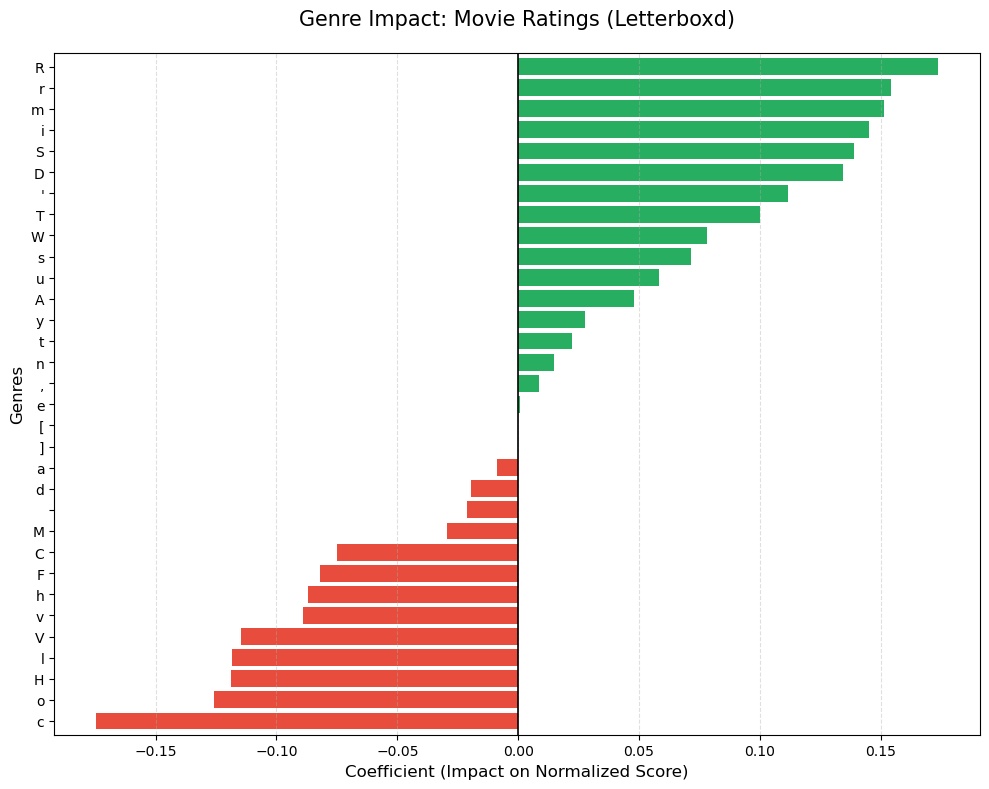

In [30]:
# Chart 1: Letterboxd -- genre effect on normalized scoreS
mlb_lb = MultiLabelBinarizer()
genre_encoded = pd.DataFrame(
    mlb_lb.fit_transform(cleaned_letterboxd_movies['Genres']),
    columns=mlb_lb.classes_,
    index=cleaned_letterboxd_movies.index
)

X = genre_encoded
Y = cleaned_letterboxd_movies['norm_score']

lm = LinearRegression().fit(X, Y)
coefficients = pd.Series(lm.coef_, index=mlb_lb.classes_).sort_values()

plt.figure(figsize=(10, 8))

colors = ['#27ae60' if x > 0 else '#e74c3c' for x in coefficients]

coefficients.plot(kind='barh', color=colors, width=0.8)

plt.title('Genre Impact: Movie Ratings (Letterboxd)', fontsize=15, pad=20)
plt.xlabel('Coefficient (Impact on Normalized Score)', fontsize=12)
plt.ylabel('Genres', fontsize=12)

plt.axvline(0, color='black', linewidth=1.2)
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()



In [31]:
# Chart 2: Goodreads -- genre effect on normalized book rating

mlb_books = MultiLabelBinarizer()
X_books = pd.DataFrame(
    mlb_books.fit_transform(cleaned_goodreads_books['genres_list']),
    columns=mlb_books.classes_,
    index=cleaned_goodreads_books.index
)

y_books = cleaned_goodreads_books['norm_score']
lm_books = LinearRegression().fit(X_books, y_books)
coef_books = pd.Series(lm_books.coef_, index=mlb_books.classes_).sort_values()

plt.figure(figsize=(12, len(coef_books) * 0.2))

colors = ['#27ae60' if x > 0 else '#e74c3c' for x in coef_books]

coef_books.plot(kind='barh', color=colors, width=0.8)

plt.title('Genre Impact: Literature Ratings (Goodreads)', fontsize=15, pad=20)
plt.xlabel('Coefficient (Impact on Normalized Score)', fontsize=12)
plt.ylabel('Book Genres', fontsize=12)
plt.axvline(0, color='black', linewidth=1.2)
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

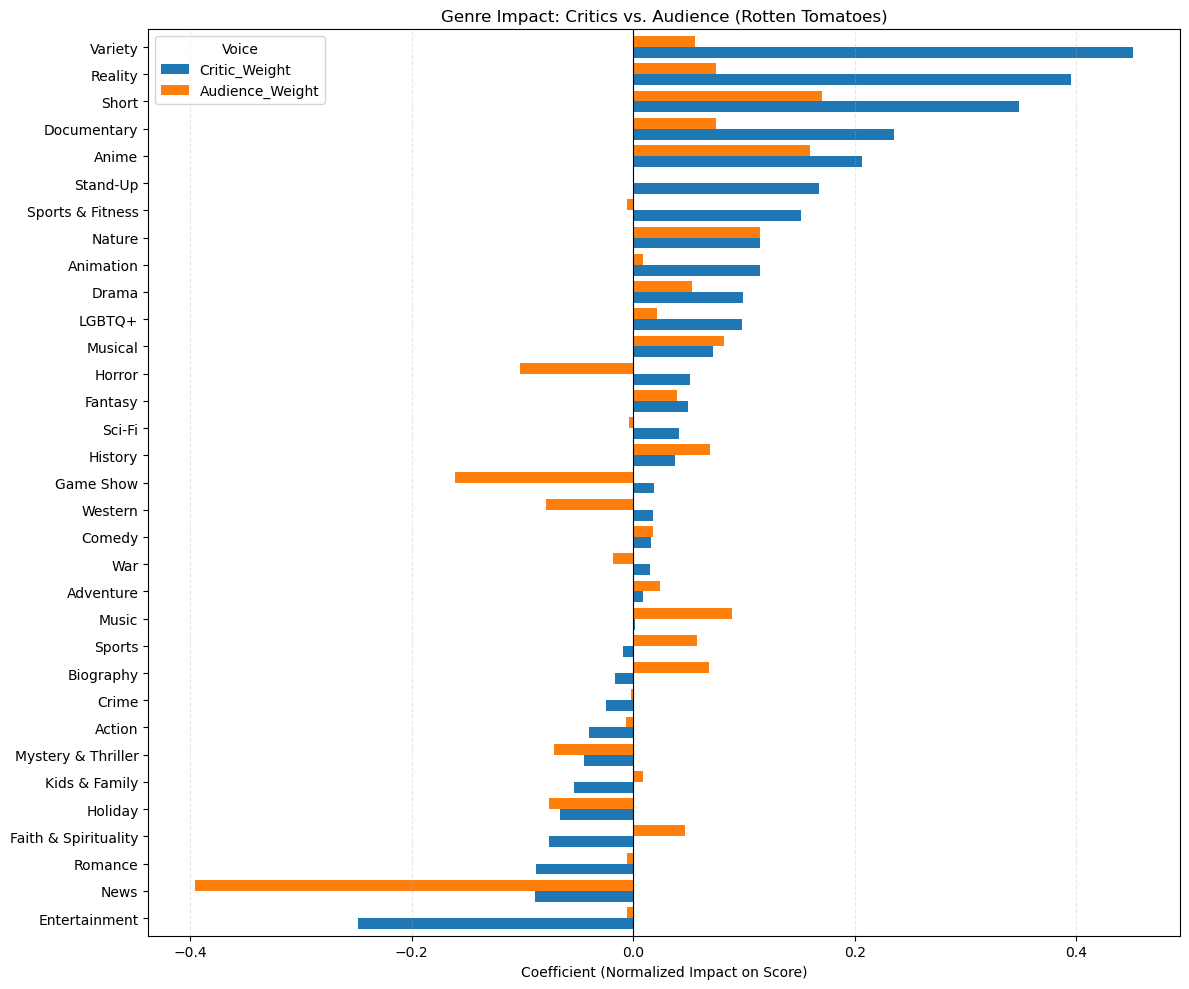

In [33]:
# Chart 3: Rotten Tomatoes -- Critics vs. Audience side-by-side
mlb = MultiLabelBinarizer()
X = pd.DataFrame(
    mlb.fit_transform(cleaned_rotten_tomatoes_movies['genres_list']),
    columns=mlb.classes_,
    index=cleaned_rotten_tomatoes_movies.index
)

y_critic = cleaned_rotten_tomatoes_movies['norm_critic'].fillna(cleaned_rotten_tomatoes_movies['norm_critic'].median())
y_audience = cleaned_rotten_tomatoes_movies['norm_audience'].fillna(cleaned_rotten_tomatoes_movies['norm_audience'].median())

# critic model
lm_critic = LinearRegression().fit(X, y_critic)
coef_critic = pd.Series(lm_critic.coef_, index=mlb.classes_)

# audience model
lm_audience = LinearRegression().fit(X, y_audience)
coef_audience = pd.Series(lm_audience.coef_, index=mlb.classes_)

rt_weights = pd.DataFrame({
    'Critic_Weight': coef_critic,
    'Audience_Weight': coef_audience
}).sort_values('Critic_Weight', ascending=False)

rt_weights.sort_values('Critic_Weight').plot(kind='barh', figsize=(12, 10), width=0.8)
plt.title('Genre Impact: Critics vs. Audience (Rotten Tomatoes)')
plt.xlabel('Coefficient (Normalized Impact on Score)')
plt.axvline(0, color='black', linewidth=0.8)
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.legend(title="Voice")
plt.tight_layout()
plt.show()

In [34]:
mlb_lb = MultiLabelBinarizer()
mlb_lb.fit(cleaned_letterboxd_movies['Genres'])

mlb_rt = MultiLabelBinarizer()
mlb_rt.fit(cleaned_rotten_tomatoes_movies['genres_list'])

mlb_books = MultiLabelBinarizer()
mlb_books.fit(cleaned_goodreads_books['genres_list'])

genre_counts_summary = {
    "Letterboxd": len(mlb_lb.classes_),
    "Rotten Tomatoes": len(mlb_rt.classes_),
    "Goodreads": len(mlb_books.classes_)
}

for platform, count in genre_counts_summary.items():
    print(f"{platform}: {count} unique genres")

Letterboxd: 32 unique genres
Rotten Tomatoes: 33 unique genres
Goodreads: 754 unique genres


In [35]:
def get_extremes(series, n=5):
    return list(series.nlargest(n).index) + list(series.nsmallest(n).index)

# collect all unique "extreme" genres from all models
extreme_genres = set()
extreme_genres.update(get_extremes(coefficients))   # letterboxd
extreme_genres.update(get_extremes(coef_critic))    # rt critics
extreme_genres.update(get_extremes(coef_audience))  # rt audience
extreme_genres.update(get_extremes(coef_books))     # goodreads

extreme_genres = sorted(list(extreme_genres))

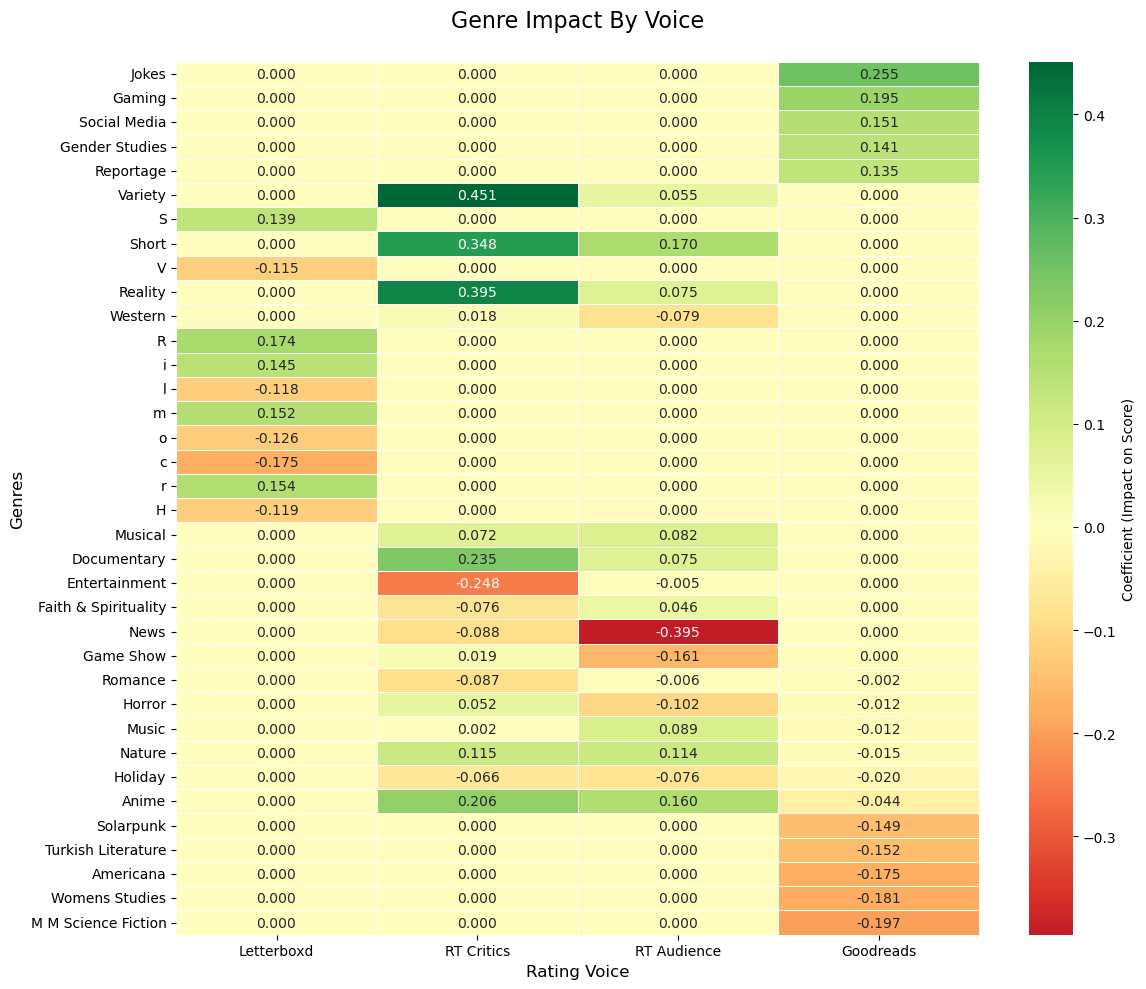

In [36]:
meta_data = []
for g in extreme_genres:
    meta_data.append({
        'Genre': g,
        'Letterboxd': coefficients.get(g, 0),
        'RT Critics': coef_critic.get(g, 0),
        'RT Audience': coef_audience.get(g, 0),
        'Goodreads': coef_books.get(g, 0)
    })

df_meta = pd.DataFrame(meta_data).set_index('Genre')

df_meta_sorted = df_meta.sort_values('Goodreads', ascending=False)

plt.figure(figsize=(12, 10))
sns.heatmap(df_meta_sorted,
            annot=True,
            fmt=".3f",
            cmap='RdYlGn',
            center=0,
            linewidths=.5,
            cbar_kws={'label': 'Coefficient (Impact on Score)'})

plt.title('Genre Impact By Voice', fontsize=16, pad=25)
plt.xlabel('Rating Voice', fontsize=12)
plt.ylabel('Genres', fontsize=12)

plt.tight_layout()
plt.show()

## Conclusion -- Research Question 2

**Letterboxd:** Genre is a strong predictor of audience rating. The R^2 score is roughly 0.50, meaning genre tags alone explain about half of the variance in Letterboxd scores. Drama has the largest positive coefficient by a wide margin. Animation and Western also skew positively. Horror has the largest negative coefficient, followed by Family, Comedy, and Action.

*Goodreads (literature):* The Goodreads graph is far noisier because tags are reader-supplied and highly fine-grained. Niche tags (Gaming, Social Media, Gender Studies) have the highest positive coefficients, likely reflecting small but enthusiastic readerships inflating average ratings. The model R^2 is lower than for film, indicating coarse genre tags are less predictive of book ratings.

### Cross-medium comparison

Drama/serious narrative genres are positively rated across both film and literature. Horror's extreme negative effect is film-specific as horror literature does not show the same pattern, likely because book horror readers are a self-selected enthusiast audience.

### Rotten Tomatoes -- Critics vs. Audience Comparisions:

Both critics and audiences show roughly the same directionality (Documentary, Drama, and Animation positive; Horror, Thriller, Comedy negative), but the magnitude differs. Critics respond more strongly to Documentary and Art House genres; audiences are relatively more tolerant of Horror and Action.


### Genre Impact Heatmap

The heatmap makes the critic/audience split very readable. Variety (0.451) and Reality (0.395) are huge for RT Critics but near zero for audiences. The Goodreads column is largely decorative for mainstream genres (almost all near zero) except for the niche community genres at the top, reinforcing the point that Goodreads genre tags reflect community enthusiasm more than generalizable quality signals.